In [1]:
!pip install pandas numpy matplotlib seaborn


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

In [3]:
print("All libraries imported successfully!")

All libraries imported successfully!


In [4]:
import os

print("Current Working Directory:")
print(os.getcwd())

Current Working Directory:
C:\Users\Niharika Negi\Documents\E-Commerce-Sales-Analysis


In [6]:
dataset_path = r"C:\Users\Niharika Negi\OneDrive\Desktop\E-Commerce-Sales-Analysis\datasets"

print(os.listdir(dataset_path))

['olist_customers_dataset.csv', 'olist_geolocation_dataset.csv', 'olist_orders_dataset.csv', 'olist_order_items_dataset.csv', 'olist_order_payments_dataset.csv', 'olist_order_reviews_dataset.csv', 'olist_products_dataset.csv', 'olist_sellers_dataset.csv', 'product_category_name_translation.csv']


In [7]:
customers = pd.read_csv(os.path.join(dataset_path, "olist_customers_dataset.csv"))

orders = pd.read_csv(os.path.join(dataset_path, "olist_orders_dataset.csv"))

order_items = pd.read_csv(os.path.join(dataset_path, "olist_order_items_dataset.csv"))

products = pd.read_csv(os.path.join(dataset_path, "olist_products_dataset.csv"))

reviews = pd.read_csv(os.path.join(dataset_path, "olist_order_reviews_dataset.csv"))

sellers = pd.read_csv(os.path.join(dataset_path, "olist_sellers_dataset.csv"))

payments = pd.read_csv(os.path.join(dataset_path, "olist_order_payments_dataset.csv"))

category_translation = pd.read_csv(os.path.join(dataset_path, "product_category_name_translation.csv"))

In [8]:
print("Orders Dataset:", orders.shape)
print("Order Items Dataset:", order_items.shape)
print("Products Dataset:", products.shape)
print("Customers Dataset:", customers.shape)
print("Reviews Dataset:", reviews.shape)

Orders Dataset: (99441, 8)
Order Items Dataset: (112650, 7)
Products Dataset: (32951, 9)
Customers Dataset: (99441, 5)
Reviews Dataset: (99224, 7)


In [9]:
orders.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


In [10]:
orders.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   order_id                       99441 non-null  object
 1   customer_id                    99441 non-null  object
 2   order_status                   99441 non-null  object
 3   order_purchase_timestamp       99441 non-null  object
 4   order_approved_at              99281 non-null  object
 5   order_delivered_carrier_date   97658 non-null  object
 6   order_delivered_customer_date  96476 non-null  object
 7   order_estimated_delivery_date  99441 non-null  object
dtypes: object(8)
memory usage: 6.1+ MB


In [11]:
orders.describe(include='all')

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
count,99441,99441,99441,99441,99281,97658,96476,99441
unique,99441,99441,8,98875,90733,81018,95664,459
top,66dea50a8b16d9b4dee7af250b4be1a5,edb027a75a1449115f6b43211ae02a24,delivered,2018-08-02 12:05:26,2018-02-27 04:31:10,2018-05-09 15:48:00,2018-05-08 19:36:48,2017-12-20 00:00:00
freq,1,1,96478,3,9,47,3,522


In [12]:
print("Missing Values in Orders:")
print(orders.isnull().sum())

Missing Values in Orders:
order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64


In [13]:
print("Duplicate Records:", orders.duplicated().sum())

Duplicate Records: 0


In [14]:
datasets = {
    "Customers": customers,
    "Orders": orders,
    "Order Items": order_items,
    "Products": products,
    "Reviews": reviews,
    "Sellers": sellers,
    "Payments": payments
}

for name, df in datasets.items():
    print("\n------------------------------")
    print(name)
    print("------------------------------")
    print("Shape:", df.shape)
    print("Missing Values:", df.isnull().sum().sum())
    print("Duplicate Rows:", df.duplicated().sum())


------------------------------
Customers
------------------------------
Shape: (99441, 5)
Missing Values: 0
Duplicate Rows: 0

------------------------------
Orders
------------------------------
Shape: (99441, 8)
Missing Values: 4908
Duplicate Rows: 0

------------------------------
Order Items
------------------------------
Shape: (112650, 7)
Missing Values: 0
Duplicate Rows: 0

------------------------------
Products
------------------------------
Shape: (32951, 9)
Missing Values: 2448
Duplicate Rows: 0

------------------------------
Reviews
------------------------------
Shape: (99224, 7)
Missing Values: 145903
Duplicate Rows: 0

------------------------------
Sellers
------------------------------
Shape: (3095, 4)
Missing Values: 0
Duplicate Rows: 0

------------------------------
Payments
------------------------------
Shape: (103886, 5)
Missing Values: 0
Duplicate Rows: 0


Data Exploration

In [15]:
print("MISSING VALUES - ORDERS")
print(orders.isnull().sum())

print("\nMISSING VALUES - PRODUCTS")
print(products.isnull().sum())

print("\nMISSING VALUES - REVIEWS")
print(reviews.isnull().sum())

MISSING VALUES - ORDERS
order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64

MISSING VALUES - PRODUCTS
product_id                      0
product_category_name         610
product_name_lenght           610
product_description_lenght    610
product_photos_qty            610
product_weight_g                2
product_length_cm               2
product_height_cm               2
product_width_cm                2
dtype: int64

MISSING VALUES - REVIEWS
review_id                      0
order_id                       0
review_score                   0
review_comment_title       87656
review_comment_message     58247
review_creation_date           0
review_answer_timestamp        0
dtype: int64


In [18]:
def missing_analysis(df, name):
    
    missing = pd.DataFrame({
        'Missing Values': df.isnull().sum(),
        'Missing Percentage': (df.isnull().sum() / len(df)) * 100
    })
    
    missing = missing[missing['Missing Values'] > 0]
    
    print("\n", name)
    print(missing.sort_values(
        by='Missing Percentage', ascending=False
    ))

missing_analysis(orders, "Orders")
missing_analysis(products, "Products")
missing_analysis(reviews, "Reviews")


 Orders
                               Missing Values  Missing Percentage
order_delivered_customer_date            2965            2.981668
order_delivered_carrier_date             1783            1.793023
order_approved_at                         160            0.160899

 Products
                            Missing Values  Missing Percentage
product_category_name                  610            1.851234
product_name_lenght                    610            1.851234
product_description_lenght             610            1.851234
product_photos_qty                     610            1.851234
product_weight_g                         2            0.006070
product_length_cm                        2            0.006070
product_height_cm                        2            0.006070
product_width_cm                         2            0.006070

 Reviews
                        Missing Values  Missing Percentage
review_comment_title             87656           88.341530
review_comment_messag

In [17]:
date_columns = [
    'order_purchase_timestamp',
    'order_approved_at',
    'order_delivered_carrier_date',
    'order_delivered_customer_date',
    'order_estimated_delivery_date'
]

for col in date_columns:
    orders[col] = pd.to_datetime(orders[col], errors='coerce')

orders.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype         
---  ------                         --------------  -----         
 0   order_id                       99441 non-null  object        
 1   customer_id                    99441 non-null  object        
 2   order_status                   99441 non-null  object        
 3   order_purchase_timestamp       99441 non-null  datetime64[ns]
 4   order_approved_at              99281 non-null  datetime64[ns]
 5   order_delivered_carrier_date   97658 non-null  datetime64[ns]
 6   order_delivered_customer_date  96476 non-null  datetime64[ns]
 7   order_estimated_delivery_date  99441 non-null  datetime64[ns]
dtypes: datetime64[ns](5), object(3)
memory usage: 6.1+ MB


In [19]:
print(orders['order_status'].value_counts())

order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64


In [20]:
missing_delivery = orders[
    orders['order_delivered_customer_date'].isnull()
]

print(missing_delivery['order_status'].value_counts())

order_status
shipped        1107
canceled        619
unavailable     609
invoiced        314
processing      301
delivered         8
created           5
approved          2
Name: count, dtype: int64


In [21]:
missing_products = products[
    products['product_category_name'].isnull()
]

print("Missing Category Rows:", len(missing_products))

missing_products.head(10)

Missing Category Rows: 610


,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
105,a41e356c76fab66334f36de622ecbd3a,NaN,NaN,NaN,NaN,650.0,17.0,14.0,12.0
128,d8dee61c2034d6d075997acef1870e9b,NaN,NaN,NaN,NaN,300.0,16.0,7.0,20.0
145,56139431d72cd51f19eb9f7dae4d1617,NaN,NaN,NaN,NaN,200.0,20.0,20.0,20.0
154,46b48281eb6d663ced748f324108c733,NaN,NaN,NaN,NaN,18500.0,41.0,30.0,41.0
197,5fb61f482620cb672f5e586bb132eae9,NaN,NaN,NaN,NaN,300.0,35.0,7.0,12.0
244,e10758160da97891c2fdcbc35f0f031d,NaN,NaN,NaN,NaN,2200.0,16.0,2.0,11.0
294,39e3b9b12cd0bf8ee681bbc1c130feb5,NaN,NaN,NaN,NaN,300.0,16.0,7.0,11.0
299,794de06c32a626a5692ff50e4985d36f,NaN,NaN,NaN,NaN,300.0,18.0,8.0,14.0
347,7af3e2da474486a3519b0cba9dea8ad9,NaN,NaN,NaN,NaN,200.0,22.0,14.0,14.0
428,629beb8e7317703dcc5f35b5463fd20e,NaN,NaN,NaN,NaN,1400.0,25.0,25.0,25.0


In [22]:
print("Total Reviews:", len(reviews))

print("Missing Titles:",
      reviews['review_comment_title'].isnull().sum())

print("Missing Messages:",
      reviews['review_comment_message'].isnull().sum())

print("\nReview Score Distribution:")

print(reviews['review_score'].value_counts().sort_index())

Total Reviews: 99224
Missing Titles: 87656
Missing Messages: 58247

Review Score Distribution:
review_score
1    11424
2     3151
3     8179
4    19142
5    57328
Name: count, dtype: int64


In [23]:
# Creating separate copies for data cleaning

customers_clean = customers.copy()
orders_clean = orders.copy()
order_items_clean = order_items.copy()
products_clean = products.copy()
reviews_clean = reviews.copy()
sellers_clean = sellers.copy()
payments_clean = payments.copy()

print("All cleaned dataset copies created successfully!")

All cleaned dataset copies created successfully!


In [24]:
date_columns = [
    'order_purchase_timestamp',
    'order_approved_at',
    'order_delivered_carrier_date',
    'order_delivered_customer_date',
    'order_estimated_delivery_date'
]

for col in date_columns:
    orders_clean[col] = pd.to_datetime(
        orders_clean[col],
        errors='coerce'
    )

print(orders_clean[date_columns].dtypes)

order_purchase_timestamp         datetime64[ns]
order_approved_at                datetime64[ns]
order_delivered_carrier_date     datetime64[ns]
order_delivered_customer_date    datetime64[ns]
order_estimated_delivery_date    datetime64[ns]
dtype: object


In [25]:
missing_dimensions = products_clean[
    products_clean['product_weight_g'].isnull()
]

print(missing_dimensions)

                             product_id product_category_name  \
8578   09ff539a621711667c43eba6a3bd8466                 bebes   
18851  5eb564652db742ff8f28759cd8d2652a                   NaN   

       product_name_lenght  product_description_lenght  product_photos_qty  \
8578                  60.0                       865.0                 3.0   
18851                  NaN                         NaN                 NaN   

       product_weight_g  product_length_cm  product_height_cm  \
8578                NaN                NaN                NaN   
18851               NaN                NaN                NaN   

       product_width_cm  
8578                NaN  
18851               NaN  


In [26]:
products_clean['product_category_name'] = (
    products_clean['product_category_name'].fillna('unknown')
)

print("Missing Categories After Cleaning:")
print(products_clean['product_category_name'].isnull().sum())

Missing Categories After Cleaning:
0


In [27]:
reviews_clean['review_comment_title'] = (
    reviews_clean['review_comment_title'].fillna('Not Provided')
)

reviews_clean['review_comment_message'] = (
    reviews_clean['review_comment_message'].fillna('Not Provided')
)

print(reviews_clean.isnull().sum())

review_id                  0
order_id                   0
review_score               0
review_comment_title       0
review_comment_message     0
review_creation_date       0
review_answer_timestamp    0
dtype: int64


In [28]:
reviews_clean['review_comment_title'] = (
    reviews_clean['review_comment_title'].fillna('Not Provided')
)

reviews_clean['review_comment_message'] = (
    reviews_clean['review_comment_message'].fillna('Not Provided')
)

print("Missing Values After Cleaning:")
print(reviews_clean.isnull().sum())

Missing Values After Cleaning:
review_id                  0
order_id                   0
review_score               0
review_comment_title       0
review_comment_message     0
review_creation_date       0
review_answer_timestamp    0
dtype: int64


In [29]:
cleaned_datasets = {
    "Customers": customers_clean,
    "Orders": orders_clean,
    "Order Items": order_items_clean,
    "Products": products_clean,
    "Reviews": reviews_clean,
    "Sellers": sellers_clean,
    "Payments": payments_clean
}

for name, df in cleaned_datasets.items():
    print(name, ":", df.duplicated().sum(), "duplicate rows")

Customers : 0 duplicate rows
Orders : 0 duplicate rows
Order Items : 0 duplicate rows
Products : 0 duplicate rows
Reviews : 0 duplicate rows
Sellers : 0 duplicate rows
Payments : 0 duplicate rows


In [30]:
print("ORDERS")
print(orders_clean.isnull().sum())

print("\nPRODUCTS")
print(products_clean.isnull().sum())

print("\nREVIEWS")
print(reviews_clean.isnull().sum())

ORDERS
order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64

PRODUCTS
product_id                      0
product_category_name           0
product_name_lenght           610
product_description_lenght    610
product_photos_qty            610
product_weight_g                2
product_length_cm               2
product_height_cm               2
product_width_cm                2
dtype: int64

REVIEWS
review_id                  0
order_id                   0
review_score               0
review_comment_title       0
review_comment_message     0
review_creation_date       0
review_answer_timestamp    0
dtype: int64


In [31]:
# Numerical columns with missing values

numeric_columns = [
    'product_name_lenght',
    'product_description_lenght',
    'product_photos_qty',
    'product_weight_g',
    'product_length_cm',
    'product_height_cm',
    'product_width_cm'
]

# Fill missing values using median

for col in numeric_columns:
    median_value = products_clean[col].median()
    products_clean[col] = products_clean[col].fillna(median_value)

print("Missing Values After Product Cleaning:")
print(products_clean.isnull().sum())

Missing Values After Product Cleaning:
product_id                    0
product_category_name         0
product_name_lenght           0
product_description_lenght    0
product_photos_qty            0
product_weight_g              0
product_length_cm             0
product_height_cm             0
product_width_cm              0
dtype: int64


In [32]:
delivered_missing = orders_clean[
    (orders_clean['order_status'] == 'delivered') &
    (orders_clean['order_delivered_customer_date'].isnull())
]

print("Delivered Orders with Missing Delivery Date:")
print(delivered_missing)

Delivered Orders with Missing Delivery Date:
                               order_id                       customer_id  \
3002   2d1e2d5bf4dc7227b3bfebb81328c15f  ec05a6d8558c6455f0cbbd8a420ad34f   
20618  f5dd62b788049ad9fc0526e3ad11a097  5e89028e024b381dc84a13a3570decb4   
43834  2ebdfc4f15f23b91474edf87475f108e  29f0540231702fda0cfdee0a310f11aa   
79263  e69f75a717d64fc5ecdfae42b2e8e086  cfda40ca8dd0a5d486a9635b611b398a   
82868  0d3268bad9b086af767785e3f0fc0133  4f1d63d35fb7c8999853b2699f5c7649   
92643  2d858f451373b04fb5c984a1cc2defaf  e08caf668d499a6d643dafd7c5cc498a   
97647  ab7c89dc1bf4a1ead9d6ec1ec8968a84  dd1b84a7286eb4524d52af4256c0ba24   
98038  20edc82cf5400ce95e1afacc25798b31  28c37425f1127d887d7337f284080a0f   

      order_status order_purchase_timestamp   order_approved_at  \
3002     delivered      2017-11-28 17:44:07 2017-11-28 17:56:40   
20618    delivered      2018-06-20 06:58:43 2018-06-20 07:19:05   
43834    delivered      2018-07-01 17:05:11 2018-07-01 17:15

In [33]:
missing_approval = orders_clean[
    orders_clean['order_approved_at'].isnull()
]

print(missing_approval['order_status'].value_counts())

order_status
canceled     141
delivered     14
created        5
Name: count, dtype: int64


In [34]:
print("ORDERS MISSING VALUES:")
print(orders_clean.isnull().sum())

print("\nPRODUCTS MISSING VALUES:")
print(products_clean.isnull().sum())

print("\nREVIEWS MISSING VALUES:")
print(reviews_clean.isnull().sum())

ORDERS MISSING VALUES:
order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64

PRODUCTS MISSING VALUES:
product_id                    0
product_category_name         0
product_name_lenght           0
product_description_lenght    0
product_photos_qty            0
product_weight_g              0
product_length_cm             0
product_height_cm             0
product_width_cm              0
dtype: int64

REVIEWS MISSING VALUES:
review_id                  0
order_id                   0
review_score               0
review_comment_title       0
review_comment_message     0
review_creation_date       0
review_answer_timestamp    0
dtype: int64


In [35]:
date_columns = [
    'order_purchase_timestamp',
    'order_approved_at',
    'order_delivered_carrier_date',
    'order_delivered_customer_date',
    'order_estimated_delivery_date'
]

for col in date_columns:
    orders_clean[col] = pd.to_datetime(
        orders_clean[col],
        errors='coerce'
    )

print("Date Columns Converted Successfully!")

print(orders_clean[date_columns].dtypes)

Date Columns Converted Successfully!
order_purchase_timestamp         datetime64[ns]
order_approved_at                datetime64[ns]
order_delivered_carrier_date     datetime64[ns]
order_delivered_customer_date    datetime64[ns]
order_estimated_delivery_date    datetime64[ns]
dtype: object


In [36]:
orders_clean['purchase_year'] = (
    orders_clean['order_purchase_timestamp'].dt.year
)

orders_clean['purchase_month'] = (
    orders_clean['order_purchase_timestamp'].dt.month
)

orders_clean['purchase_month_name'] = (
    orders_clean['order_purchase_timestamp'].dt.month_name()
)

orders_clean['purchase_day'] = (
    orders_clean['order_purchase_timestamp'].dt.day
)

orders_clean['purchase_day_name'] = (
    orders_clean['order_purchase_timestamp'].dt.day_name()
)

orders_clean['purchase_hour'] = (
    orders_clean['order_purchase_timestamp'].dt.hour
)

orders_clean.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,purchase_year,purchase_month,purchase_month_name,purchase_day,purchase_day_name,purchase_hour
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,2017,10,October,2,Monday,10
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,2018,7,July,24,Tuesday,20
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,2018,8,August,8,Wednesday,8
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,2017,11,November,18,Saturday,19
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,2018,2,February,13,Tuesday,21


In [37]:
orders_items = pd.merge(
    orders_clean,
    order_items_clean,
    on='order_id',
    how='inner'
)

print("Orders + Order Items:", orders_items.shape)

orders_items.head()

Orders + Order Items: (112650, 20)


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,purchase_year,purchase_month,purchase_month_name,purchase_day,purchase_day_name,purchase_hour,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,2017,10,October,2,Monday,10,1,87285b34884572647811a353c7ac498a,3504c0cb71d7fa48d967e0e4c94d59d9,2017-10-06 11:07:15,29.99,8.72
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,2018,7,July,24,Tuesday,20,1,595fac2a385ac33a80bd5114aec74eb8,289cdb325fb7e7f891c38608bf9e0962,2018-07-30 03:24:27,118.70,22.76
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,2018,8,August,8,Wednesday,8,1,aa4383b373c6aca5d8797843e5594415,4869f7a5dfa277a7dca6462dcf3b52b2,2018-08-13 08:55:23,159.90,19.22
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,2017,11,November,18,Saturday,19,1,d0b61bfb1de832b15ba9d266ca96e5b0,66922902710d126a0e7d26b0e3805106,2017-11-23 19:45:59,45.00,27.20
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,2018,2,February,13,Tuesday,21,1,65266b2da20d04dbe00c5c2d3bb7859e,2c9e548be18521d1c43cde1c582c6de8,2018-02-19 20:31:37,19.90,8.72


In [38]:
orders_products = pd.merge(
    orders_items,
    products_clean,
    on='product_id',
    how='left'
)

print("Orders + Products:", orders_products.shape)

orders_products.head()

Orders + Products: (112650, 28)


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,purchase_year,purchase_month,...,price,freight_value,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,2017,10,...,29.99,8.72,utilidades_domesticas,40.0,268.0,4.0,500.0,19.0,8.0,13.0
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,2018,7,...,118.70,22.76,perfumaria,29.0,178.0,1.0,400.0,19.0,13.0,19.0
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,2018,8,...,159.90,19.22,automotivo,46.0,232.0,1.0,420.0,24.0,19.0,21.0
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,2017,11,...,45.00,27.20,pet_shop,59.0,468.0,3.0,450.0,30.0,10.0,20.0
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,2018,2,...,19.90,8.72,papelaria,38.0,316.0,4.0,250.0,51.0,15.0,15.0


In [39]:
orders_payments = pd.merge(
    orders_products,
    payments_clean,
    on='order_id',
    how='left'
)

print("Orders + Payments:", orders_payments.shape)

orders_payments.head()

Orders + Payments: (117604, 32)


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,purchase_year,purchase_month,...,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm,payment_sequential,payment_type,payment_installments,payment_value
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,2017,10,...,268.0,4.0,500.0,19.0,8.0,13.0,1.0,credit_card,1.0,18.12
1,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,2017,10,...,268.0,4.0,500.0,19.0,8.0,13.0,3.0,voucher,1.0,2.00
2,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,2017,10,...,268.0,4.0,500.0,19.0,8.0,13.0,2.0,voucher,1.0,18.59
3,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,2018,7,...,178.0,1.0,400.0,19.0,13.0,19.0,1.0,boleto,1.0,141.46
4,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,2018,8,...,232.0,1.0,420.0,24.0,19.0,21.0,1.0,credit_card,3.0,179.12


In [40]:
final_data = pd.merge(
    orders_payments,
    customers_clean,
    on='customer_id',
    how='left'
)

print("Final Dataset Shape:", final_data.shape)

final_data.head()

Final Dataset Shape: (117604, 36)


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,purchase_year,purchase_month,...,product_height_cm,product_width_cm,payment_sequential,payment_type,payment_installments,payment_value,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,2017,10,...,8.0,13.0,1.0,credit_card,1.0,18.12,7c396fd4830fd04220f754e42b4e5bff,3149,sao paulo,SP
1,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,2017,10,...,8.0,13.0,3.0,voucher,1.0,2.00,7c396fd4830fd04220f754e42b4e5bff,3149,sao paulo,SP
2,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,2017,10,...,8.0,13.0,2.0,voucher,1.0,18.59,7c396fd4830fd04220f754e42b4e5bff,3149,sao paulo,SP
3,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,2018,7,...,13.0,19.0,1.0,boleto,1.0,141.46,af07308b275d755c9edb36a90c618231,47813,barreiras,BA
4,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,2018,8,...,19.0,21.0,1.0,credit_card,3.0,179.12,3a653a41f6f9fc3d2a113cf8398680e8,75265,vianopolis,GO


In [41]:
payments_summary = payments_clean.groupby('order_id').agg({
    'payment_value': 'sum',
    'payment_installments': 'max',
    'payment_type': lambda x: ', '.join(x.unique())
}).reset_index()

print("Payments Summary:", payments_summary.shape)

payments_summary.head()

Payments Summary: (99440, 4)


,order_id,payment_value,payment_installments,payment_type
0,00010242fe8c5a6d1ba2dd792cb16214,72.19,2,credit_card
1,00018f77f2f0320c557190d7a144bdd3,259.83,3,credit_card
2,000229ec398224ef6ca0657da4fc703e,216.87,5,credit_card
3,00024acbcdf0a6daa1e931b038114c75,25.78,2,credit_card
4,00042b26cf59d7ce69dfabb4e55b4fd9,218.04,3,credit_card


In [42]:
final_data = pd.merge(
    orders_products,
    payments_summary,
    on='order_id',
    how='left'
)

final_data = pd.merge(
    final_data,
    customers_clean,
    on='customer_id',
    how='left'
)

print("Final Dataset:", final_data.shape)

print("Total Rows:", len(final_data))

print("Duplicate Rows:", final_data.duplicated().sum())

final_data.head()

Final Dataset: (112650, 35)
Total Rows: 112650
Duplicate Rows: 0


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,purchase_year,purchase_month,...,product_length_cm,product_height_cm,product_width_cm,payment_value,payment_installments,payment_type,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,2017,10,...,19.0,8.0,13.0,38.71,1.0,"credit_card, voucher",7c396fd4830fd04220f754e42b4e5bff,3149,sao paulo,SP
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,2018,7,...,19.0,13.0,19.0,141.46,1.0,boleto,af07308b275d755c9edb36a90c618231,47813,barreiras,BA
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,2018,8,...,24.0,19.0,21.0,179.12,3.0,credit_card,3a653a41f6f9fc3d2a113cf8398680e8,75265,vianopolis,GO
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,2017,11,...,30.0,10.0,20.0,72.20,1.0,credit_card,7c142cf63193a1473d2e66489a9ae977,59296,sao goncalo do amarante,RN
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,2018,2,...,51.0,15.0,15.0,28.62,1.0,credit_card,72632f0f9dd73dfee390c9b22eb56dd6,9195,santo andre,SP


In [43]:
final_data = pd.merge(
    final_data,
    sellers_clean,
    on='seller_id',
    how='left'
)

print("Final Dataset Shape:", final_data.shape)

print("Duplicate Rows:", final_data.duplicated().sum())

final_data.head()

Final Dataset Shape: (112650, 38)
Duplicate Rows: 0


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,purchase_year,purchase_month,...,payment_value,payment_installments,payment_type,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state,seller_zip_code_prefix,seller_city,seller_state
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,2017,10,...,38.71,1.0,"credit_card, voucher",7c396fd4830fd04220f754e42b4e5bff,3149,sao paulo,SP,9350,maua,SP
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,2018,7,...,141.46,1.0,boleto,af07308b275d755c9edb36a90c618231,47813,barreiras,BA,31570,belo horizonte,SP
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,2018,8,...,179.12,3.0,credit_card,3a653a41f6f9fc3d2a113cf8398680e8,75265,vianopolis,GO,14840,guariba,SP
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,2017,11,...,72.20,1.0,credit_card,7c142cf63193a1473d2e66489a9ae977,59296,sao goncalo do amarante,RN,31842,belo horizonte,MG
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,2018,2,...,28.62,1.0,credit_card,72632f0f9dd73dfee390c9b22eb56dd6,9195,santo andre,SP,8752,mogi das cruzes,SP


In [44]:
final_data = pd.merge(
    final_data,
    category_translation,
    on='product_category_name',
    how='left'
)

print("Final Dataset Shape:", final_data.shape)

final_data.head()

Final Dataset Shape: (112650, 39)


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,purchase_year,purchase_month,...,payment_installments,payment_type,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state,seller_zip_code_prefix,seller_city,seller_state,product_category_name_english
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,2017,10,...,1.0,"credit_card, voucher",7c396fd4830fd04220f754e42b4e5bff,3149,sao paulo,SP,9350,maua,SP,housewares
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,2018,7,...,1.0,boleto,af07308b275d755c9edb36a90c618231,47813,barreiras,BA,31570,belo horizonte,SP,perfumery
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,2018,8,...,3.0,credit_card,3a653a41f6f9fc3d2a113cf8398680e8,75265,vianopolis,GO,14840,guariba,SP,auto
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,2017,11,...,1.0,credit_card,7c142cf63193a1473d2e66489a9ae977,59296,sao goncalo do amarante,RN,31842,belo horizonte,MG,pet_shop
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,2018,2,...,1.0,credit_card,72632f0f9dd73dfee390c9b22eb56dd6,9195,santo andre,SP,8752,mogi das cruzes,SP,stationery


In [45]:
print("FINAL DATASET INFORMATION")

print("Rows:", final_data.shape[0])
print("Columns:", final_data.shape[1])

print("\nMissing Values:")
print(final_data.isnull().sum())

print("\nDuplicate Rows:")
print(final_data.duplicated().sum())

print("\nColumn Names:")
print(final_data.columns.tolist())

FINAL DATASET INFORMATION
Rows: 112650
Columns: 39

Missing Values:
order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                  15
order_delivered_carrier_date     1194
order_delivered_customer_date    2454
order_estimated_delivery_date       0
purchase_year                       0
purchase_month                      0
purchase_month_name                 0
purchase_day                        0
purchase_day_name                   0
purchase_hour                       0
order_item_id                       0
product_id                          0
seller_id                           0
shipping_limit_date                 0
price                               0
freight_value                       0
product_category_name               0
product_name_lenght                 0
product_description_lenght          0
product_photos_qty                  0
product_weight_g    

In [46]:
final_data['product_category_name_english'] = (
    final_data['product_category_name_english'].fillna('Unknown')
)

print(final_data['product_category_name_english'].isnull().sum())

0


In [47]:
final_data['total_item_amount'] = (
    final_data['price'] + final_data['freight_value']
)

final_data[['price', 'freight_value', 'total_item_amount']].head()

,price,freight_value,total_item_amount
0,29.99,8.72,38.71
1,118.70,22.76,141.46
2,159.90,19.22,179.12
3,45.00,27.20,72.20
4,19.90,8.72,28.62


In [48]:
final_data['delivery_time_days'] = (
    final_data['order_delivered_customer_date'] -
    final_data['order_purchase_timestamp']
).dt.days

final_data[['order_status', 'delivery_time_days']].head()

,order_status,delivery_time_days
0,delivered,8.0
1,delivered,13.0
2,delivered,9.0
3,delivered,13.0
4,delivered,2.0


In [49]:
final_data['delivery_delay_days'] = (
    final_data['order_delivered_customer_date'] -
    final_data['order_estimated_delivery_date']
).dt.days

final_data[['delivery_delay_days']].head()

,delivery_delay_days
0,-8.0
1,-6.0
2,-18.0
3,-13.0
4,-10.0


In [56]:
print("TOTAL ORDERS:", final_data['order_id'].nunique())

print("TOTAL CUSTOMERS:", final_data['customer_unique_id'].nunique())

print("TOTAL PRODUCTS SOLD:", final_data['order_item_id'].count())

print("TOTAL SALES REVENUE:", final_data['price'].sum())

print("TOTAL FREIGHT:", final_data['freight_value'].sum())

print("AVERAGE PRODUCT PRICE:", final_data['price'].mean())

print("AVERAGE REVIEW SCORE:",
      reviews_clean['review_score'].mean())

TOTAL ORDERS: 98666
TOTAL CUSTOMERS: 95420
TOTAL PRODUCTS SOLD: 112650
TOTAL SALES REVENUE: 13591643.700000001
TOTAL FREIGHT: 2251909.54
AVERAGE PRODUCT PRICE: 120.65373901464714
AVERAGE REVIEW SCORE: 4.08642062404257


# Graph-wise Analysis & Insights

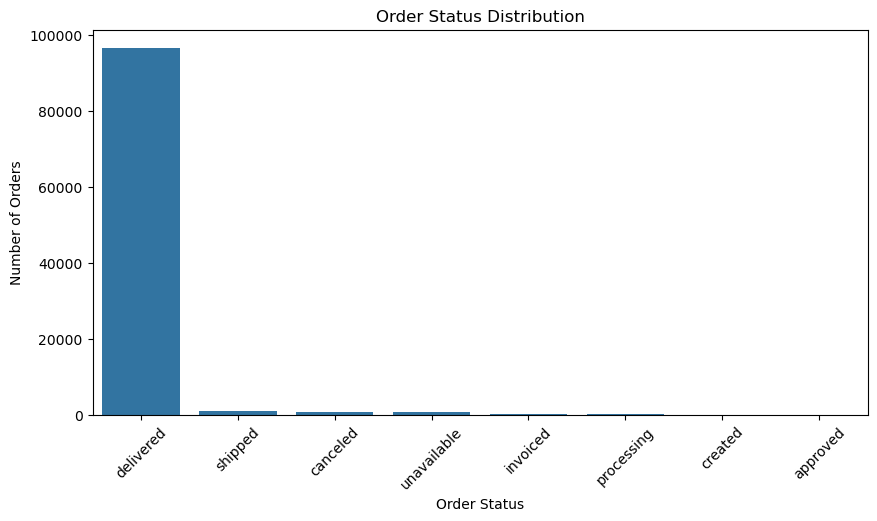

In [51]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10,5))

sns.countplot(
    data=orders_clean,
    x='order_status',
    order=orders_clean['order_status'].value_counts().index
)

plt.title("Order Status Distribution")
plt.xlabel("Order Status")
plt.ylabel("Number of Orders")
plt.xticks(rotation=45)
plt.show()

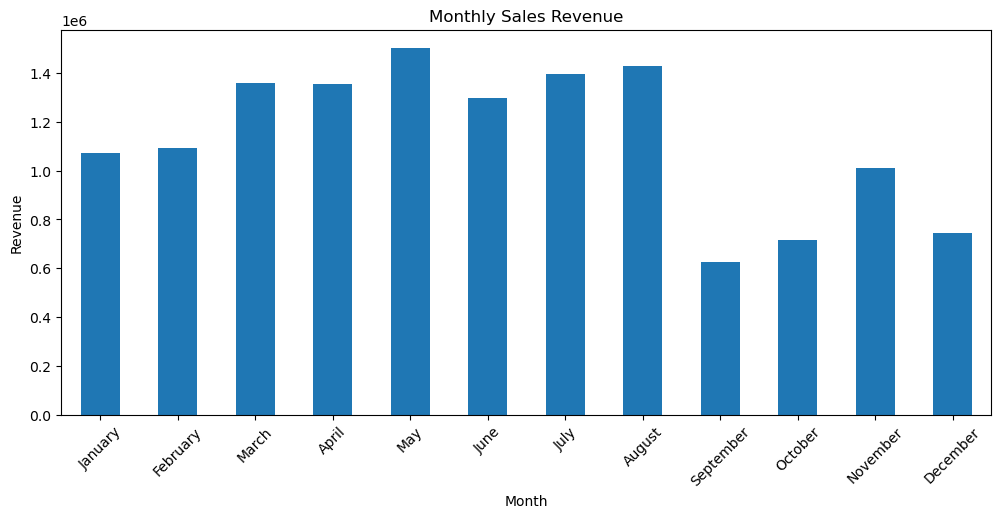

In [52]:
monthly_sales = final_data.groupby(
    'purchase_month_name'
)['price'].sum()

month_order = [
    'January', 'February', 'March', 'April',
    'May', 'June', 'July', 'August',
    'September', 'October', 'November', 'December'
]

monthly_sales = monthly_sales.reindex(month_order)

plt.figure(figsize=(12,5))

monthly_sales.plot(kind='bar')

plt.title("Monthly Sales Revenue")
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.xticks(rotation=45)
plt.show()

purchase_year
2016      49785.92
2017    6155806.98
2018    7386050.80
Name: price, dtype: float64


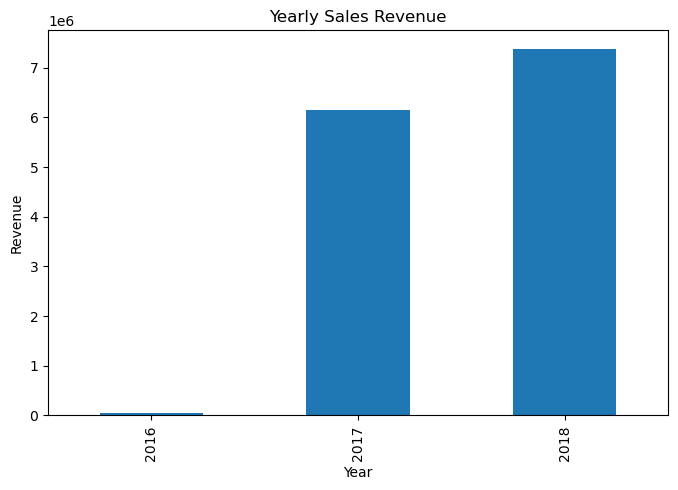

In [53]:
yearly_sales = final_data.groupby(
    'purchase_year'
)['price'].sum()

print(yearly_sales)

yearly_sales.plot(
    kind='bar',
    figsize=(8,5),
    title="Yearly Sales Revenue"
)

plt.xlabel("Year")
plt.ylabel("Revenue")
plt.show()

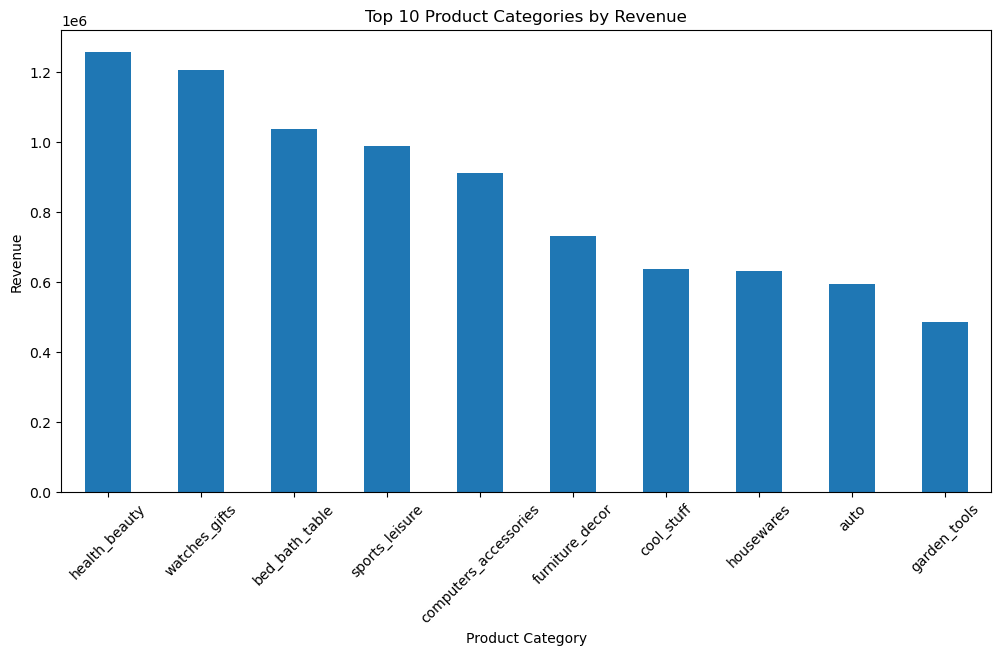

In [54]:
top_categories = final_data.groupby(
    'product_category_name_english'
)['price'].sum().sort_values(ascending=False).head(10)

plt.figure(figsize=(12,6))

top_categories.plot(kind='bar')

plt.title("Top 10 Product Categories by Revenue")
plt.xlabel("Product Category")
plt.ylabel("Revenue")
plt.xticks(rotation=45)
plt.show()

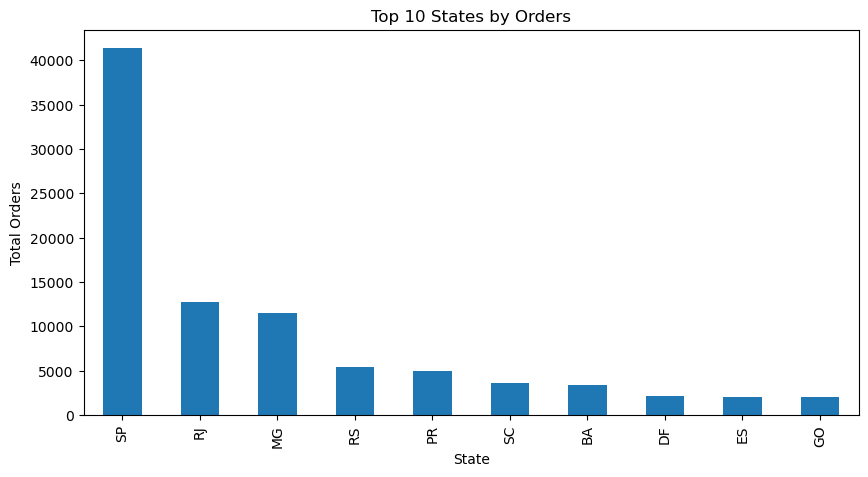

In [55]:
top_states = final_data.groupby(
    'customer_state'
)['order_id'].nunique().sort_values(ascending=False).head(10)

plt.figure(figsize=(10,5))

top_states.plot(kind='bar')

plt.title("Top 10 States by Orders")
plt.xlabel("State")
plt.ylabel("Total Orders")
plt.show()

# Customer Analysis

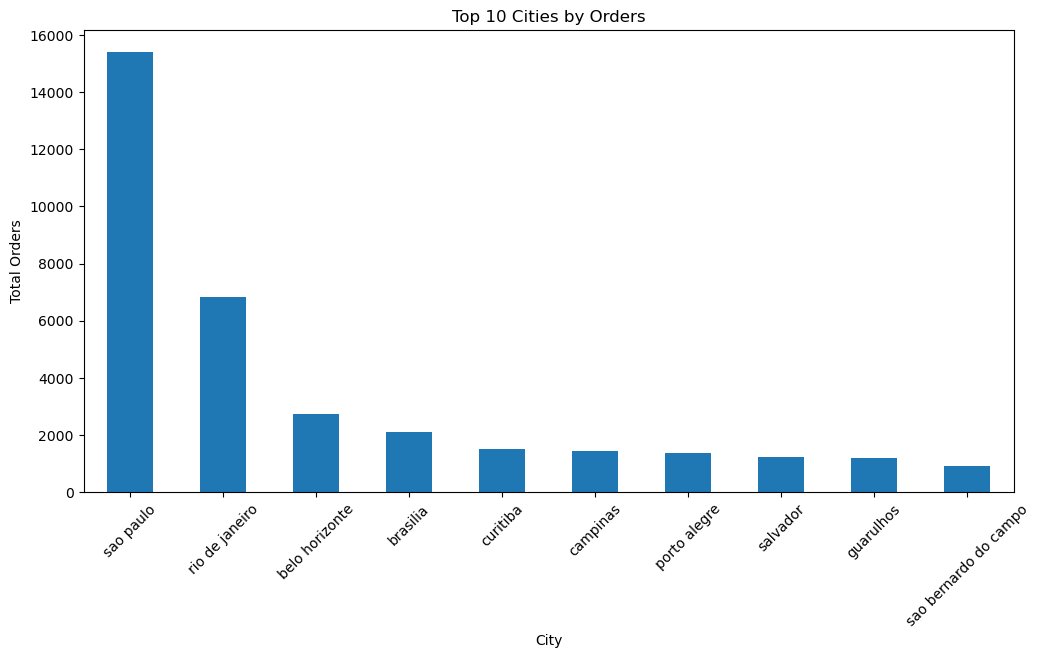

In [57]:
top_cities = final_data.groupby(
    'customer_city'
)['order_id'].nunique().sort_values(
    ascending=False
).head(10)

plt.figure(figsize=(12,6))
top_cities.plot(kind='bar')

plt.title("Top 10 Cities by Orders")
plt.xlabel("City")
plt.ylabel("Total Orders")
plt.xticks(rotation=45)
plt.show()

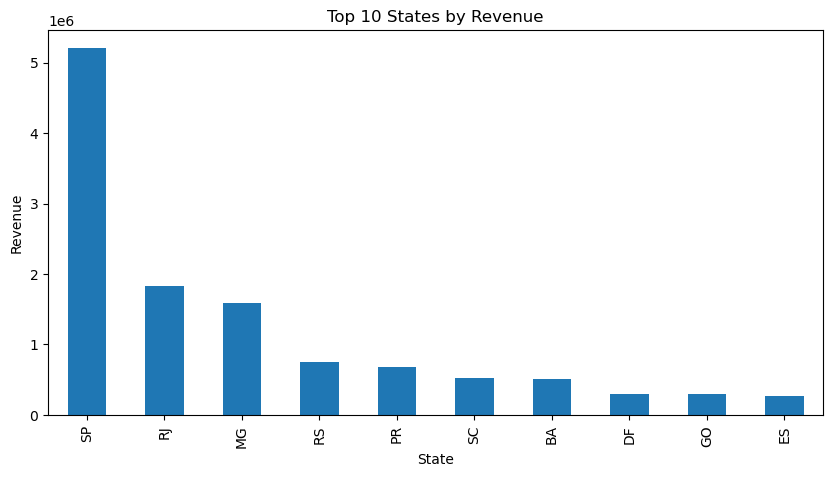

In [58]:
state_revenue = final_data.groupby(
    'customer_state'
)['price'].sum().sort_values(
    ascending=False
).head(10)

plt.figure(figsize=(10,5))
state_revenue.plot(kind='bar')

plt.title("Top 10 States by Revenue")
plt.xlabel("State")
plt.ylabel("Revenue")
plt.show()

In [59]:
order_revenue = final_data.groupby(
    'order_id'
)['price'].sum()

aov = order_revenue.mean()

print("Average Order Value:", round(aov, 2))

Average Order Value: 137.75


In [60]:
customer_orders = final_data.groupby(
    'customer_unique_id'
)['order_id'].nunique()

repeat_customers = (customer_orders > 1).sum()

print("Repeat Customers:", repeat_customers)
print("One-time Customers:", (customer_orders == 1).sum())

Repeat Customers: 2913
One-time Customers: 92507


Payment Analysis

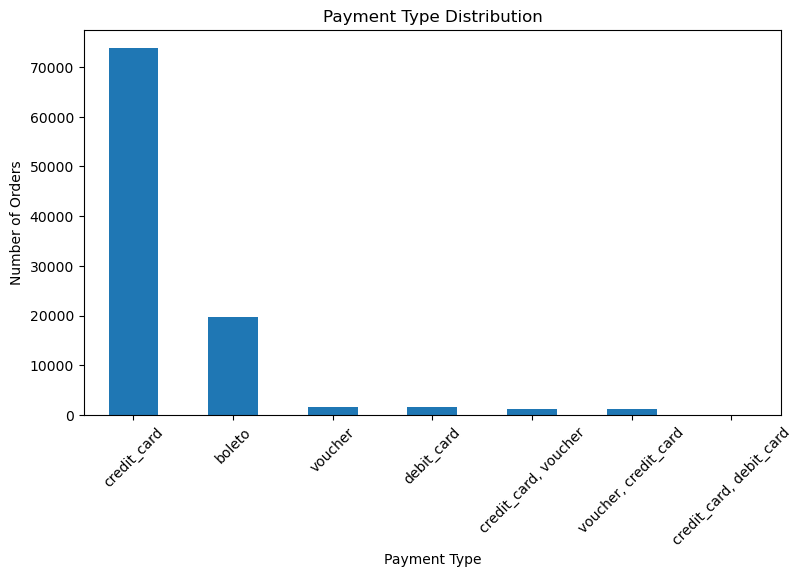

In [61]:
payment_types = final_data.groupby(
    'payment_type'
)['order_id'].nunique().sort_values(ascending=False)

plt.figure(figsize=(9,5))
payment_types.plot(kind='bar')

plt.title("Payment Type Distribution")
plt.xlabel("Payment Type")
plt.ylabel("Number of Orders")
plt.xticks(rotation=45)
plt.show()

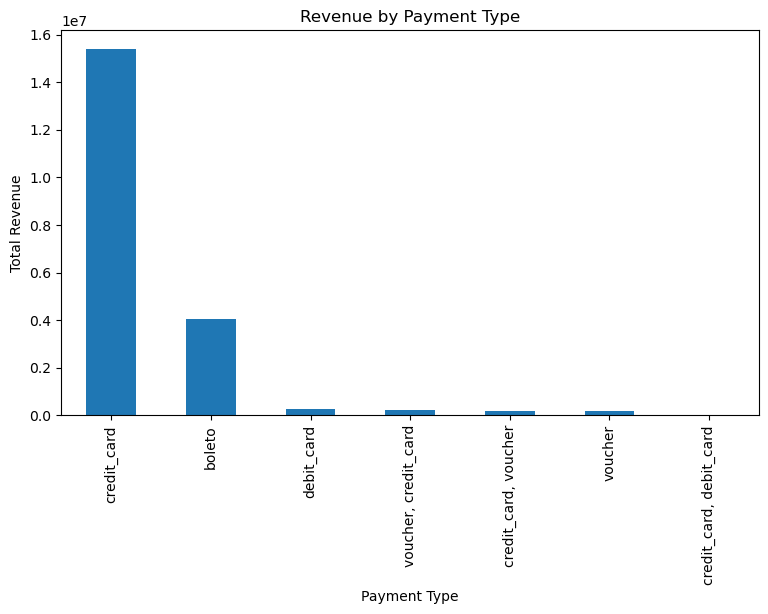

In [62]:
payment_revenue = final_data.groupby(
    'payment_type'
)['payment_value'].sum().sort_values(ascending=False)

plt.figure(figsize=(9,5))
payment_revenue.plot(kind='bar')

plt.title("Revenue by Payment Type")
plt.xlabel("Payment Type")
plt.ylabel("Total Revenue")
plt.show()

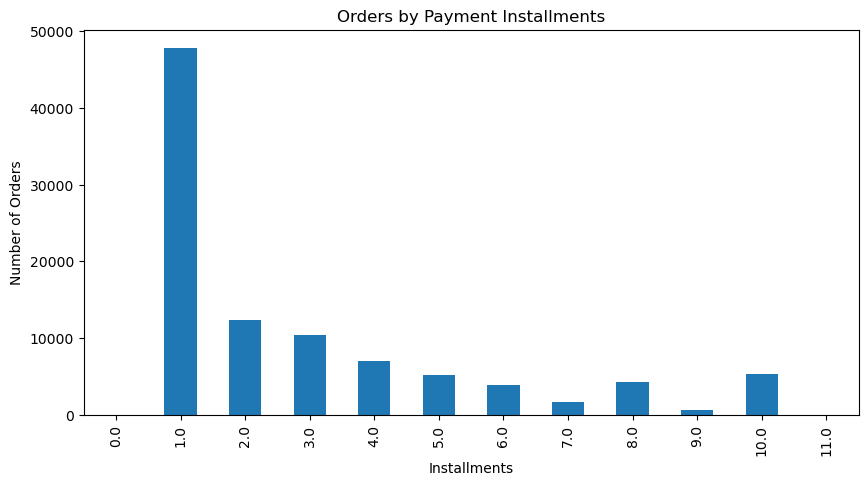

In [63]:
installments = final_data.groupby(
    'payment_installments'
)['order_id'].nunique()

plt.figure(figsize=(10,5))
installments.head(12).plot(kind='bar')

plt.title("Orders by Payment Installments")
plt.xlabel("Installments")
plt.ylabel("Number of Orders")
plt.show()

Delivery Performance Analysis

In [64]:
avg_delivery = final_data[
    'delivery_time_days'
].mean()

print("Average Delivery Time:",
      round(avg_delivery, 2), "Days")

Average Delivery Time: 12.01 Days


In [65]:
delivered_orders = final_data[
    final_data['order_status'] == 'delivered'
].copy()

delivered_orders['delivery_performance'] = (
    delivered_orders['delivery_delay_days'].apply(
        lambda x: 'Late' if x > 0
        else 'On Time or Early'
    )
)

print(delivered_orders['delivery_performance'].value_counts())

delivery_performance
On Time or Early    102933
Late                  7264
Name: count, dtype: int64


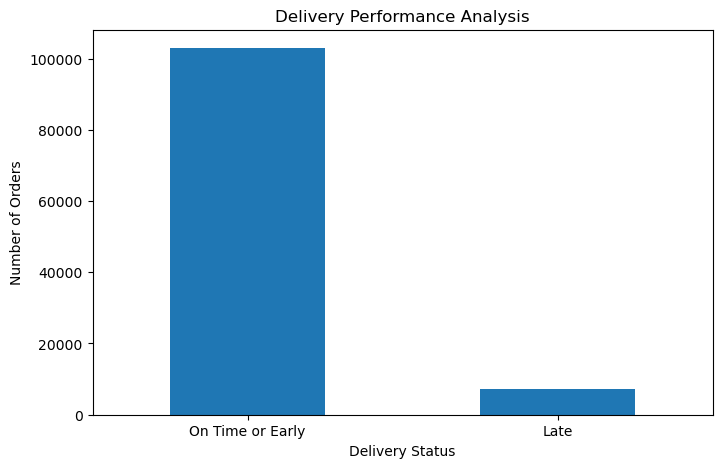

In [66]:
delivery_counts = delivered_orders[
    'delivery_performance'
].value_counts()

plt.figure(figsize=(8,5))
delivery_counts.plot(kind='bar')

plt.title("Delivery Performance Analysis")
plt.xlabel("Delivery Status")
plt.ylabel("Number of Orders")
plt.xticks(rotation=0)
plt.show()

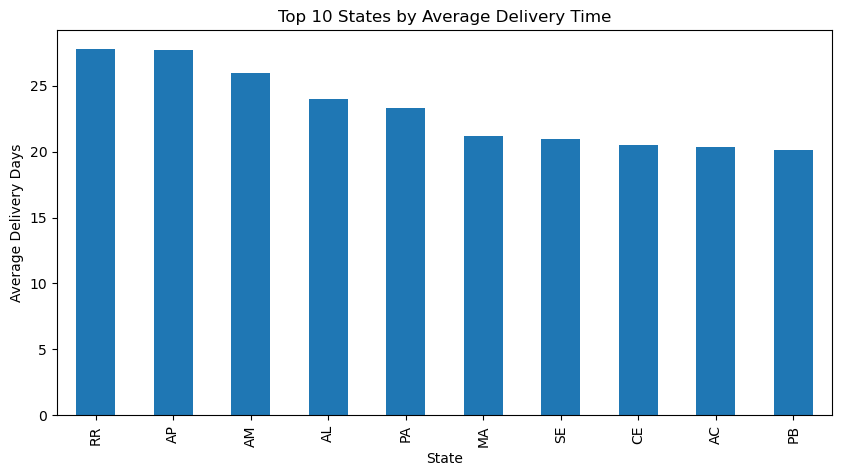

In [67]:
state_delivery = delivered_orders.groupby(
    'customer_state'
)['delivery_time_days'].mean().sort_values(
    ascending=False
).head(10)

plt.figure(figsize=(10,5))
state_delivery.plot(kind='bar')

plt.title("Top 10 States by Average Delivery Time")
plt.xlabel("State")
plt.ylabel("Average Delivery Days")
plt.show()

Seller Analysis

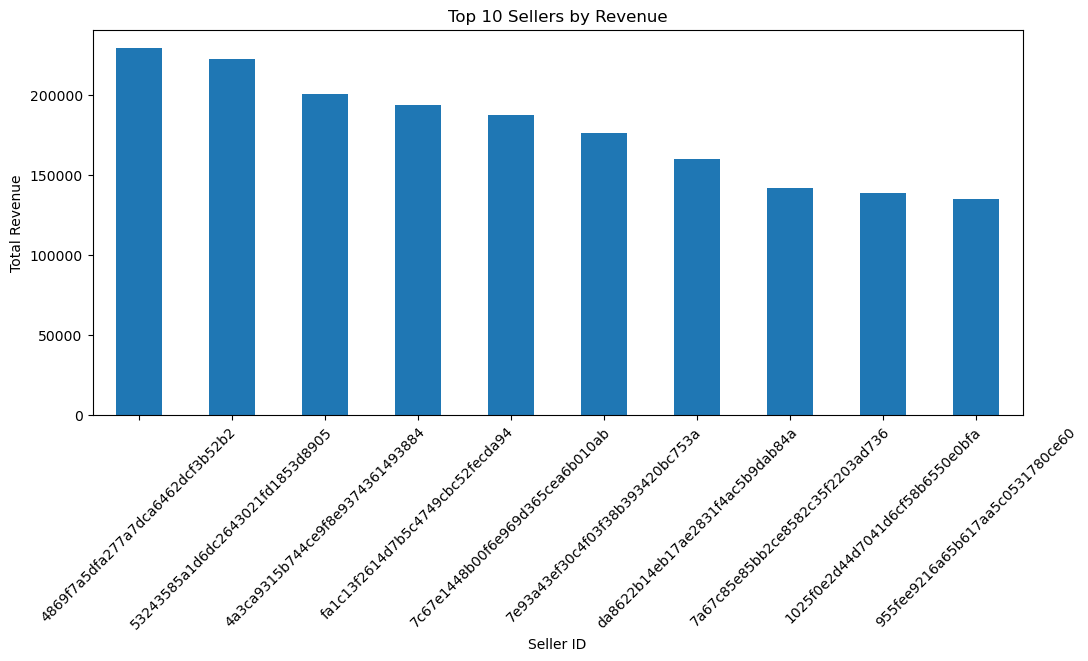

In [69]:
top_sellers = final_data.groupby(
    'seller_id'
)['price'].sum().sort_values(
    ascending=False
).head(10)

plt.figure(figsize=(12,5))
top_sellers.plot(kind='bar')

plt.title("Top 10 Sellers by Revenue")
plt.xlabel("Seller ID")
plt.ylabel("Total Revenue")
plt.xticks(rotation=45)
plt.show()

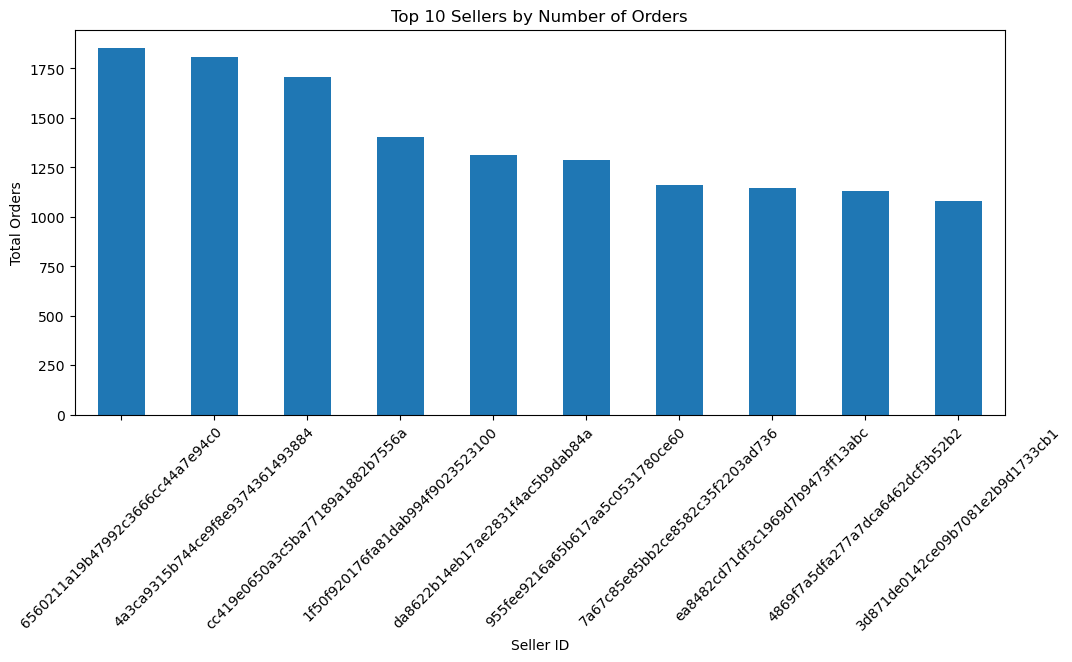

In [70]:
seller_orders = final_data.groupby(
    'seller_id'
)['order_id'].nunique().sort_values(
    ascending=False
).head(10)

plt.figure(figsize=(12,5))
seller_orders.plot(kind='bar')

plt.title("Top 10 Sellers by Number of Orders")
plt.xlabel("Seller ID")
plt.ylabel("Total Orders")
plt.xticks(rotation=45)
plt.show()

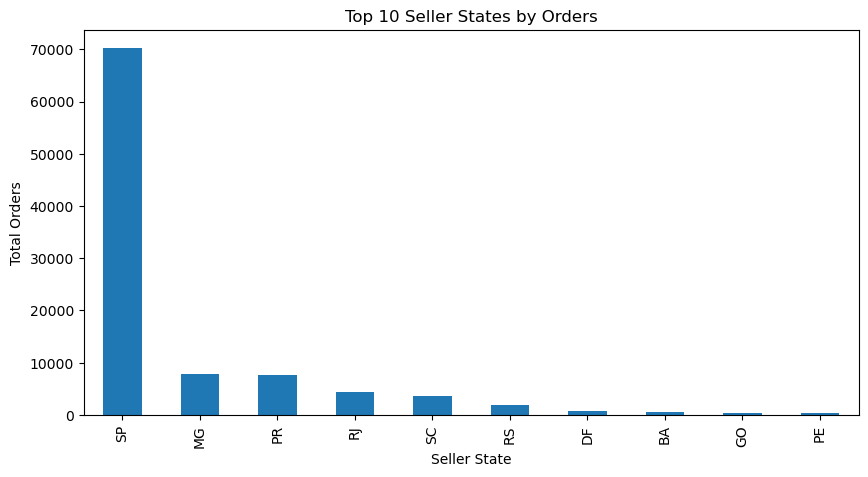

In [71]:
seller_state = final_data.groupby(
    'seller_state'
)['order_id'].nunique().sort_values(
    ascending=False
).head(10)

plt.figure(figsize=(10,5))
seller_state.plot(kind='bar')

plt.title("Top 10 Seller States by Orders")
plt.xlabel("Seller State")
plt.ylabel("Total Orders")
plt.show()

Correlation Heatmap

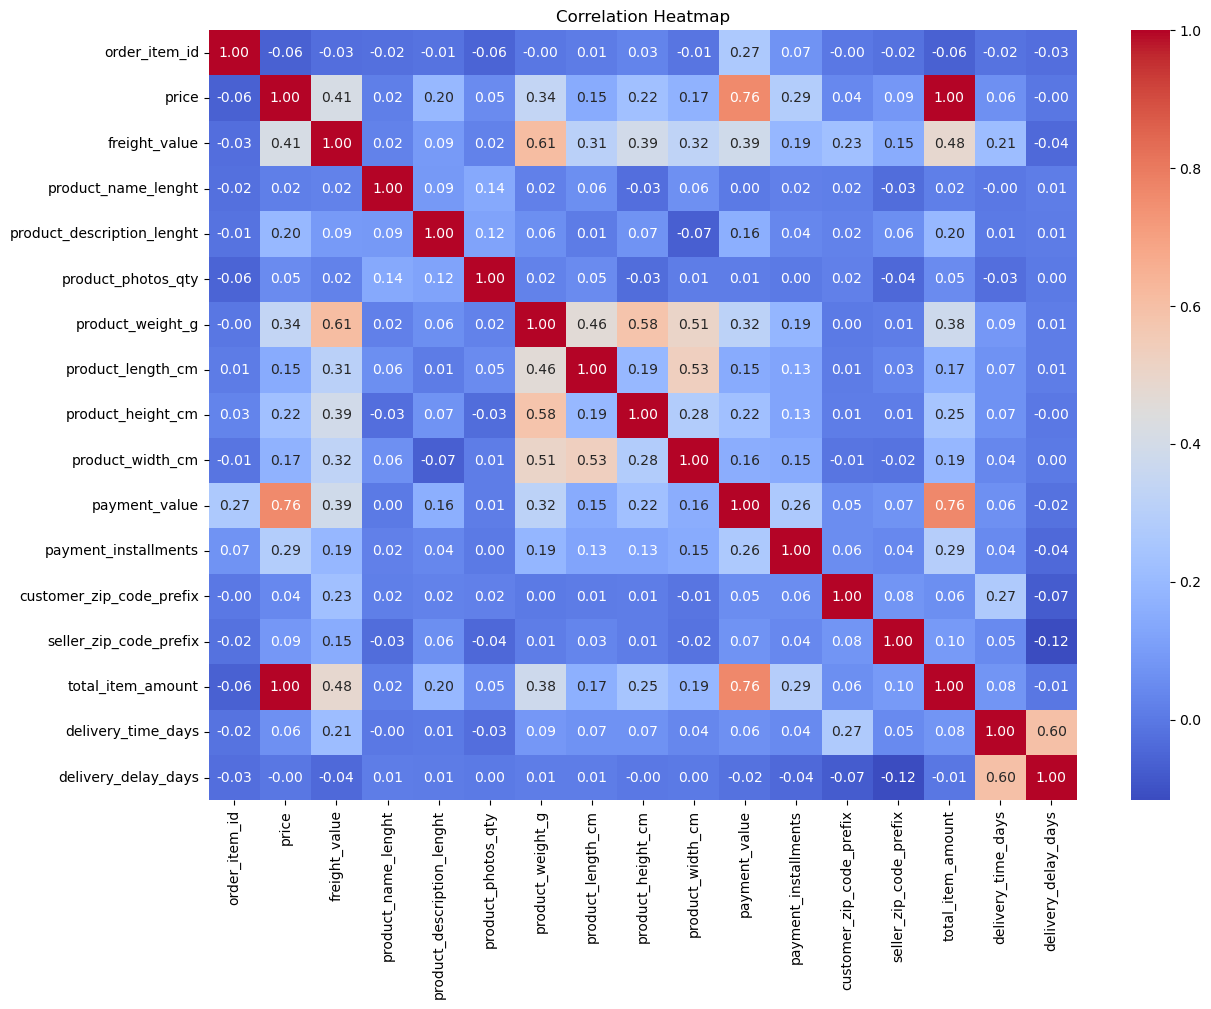

In [72]:
import seaborn as sns
import matplotlib.pyplot as plt

numeric_data = final_data.select_dtypes(
    include=['int64', 'float64']
)

correlation = numeric_data.corr()

plt.figure(figsize=(14,10))

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title("Correlation Heatmap")
plt.show()

In [73]:
final_data.to_csv(
    "Final_Ecommerce_Dataset.csv",
    index=False
)

print("Final Dataset Saved Successfully!")

Final Dataset Saved Successfully!


In [74]:
print("FINAL DATASET SHAPE:", final_data.shape)

print("\nMISSING VALUES:")
print(final_data.isnull().sum()[final_data.isnull().sum() > 0])

print("\nDUPLICATE ROWS:")
print(final_data.duplicated().sum())

print("\nDATA TYPES:")
print(final_data.dtypes)

FINAL DATASET SHAPE: (112650, 42)

MISSING VALUES:
order_approved_at                  15
order_delivered_carrier_date     1194
order_delivered_customer_date    2454
payment_value                       3
payment_installments                3
payment_type                        3
delivery_time_days               2454
delivery_delay_days              2454
dtype: int64

DUPLICATE ROWS:
0

DATA TYPES:
order_id                                 object
customer_id                              object
order_status                             object
order_purchase_timestamp         datetime64[ns]
order_approved_at                datetime64[ns]
order_delivered_carrier_date     datetime64[ns]
order_delivered_customer_date    datetime64[ns]
order_estimated_delivery_date    datetime64[ns]
purchase_year                             int32
purchase_month                            int32
purchase_month_name                      object
purchase_day                              int32
purchase_day_name       

In [75]:
final_data['product_category_name_english'] = (
    final_data['product_category_name_english'].fillna('Unknown')
)

final_data['payment_type'] = (
    final_data['payment_type'].fillna('Unknown')
)

final_data['payment_value'] = (
    final_data['payment_value'].fillna(0)
)

final_data['payment_installments'] = (
    final_data['payment_installments'].fillna(0)
)

In [76]:
final_data.to_csv(
    "Final_Ecommerce_Dataset.csv",
    index=False
)

print("Dataset Updated Successfully!")

Dataset Updated Successfully!


In [77]:
import os

print(os.getcwd())

C:\Users\Niharika Negi\Documents\E-Commerce-Sales-Analysis


In [78]:
print(os.path.abspath("Final_Ecommerce_Dataset.csv"))

C:\Users\Niharika Negi\Documents\E-Commerce-Sales-Analysis\Final_Ecommerce_Dataset.csv


In [79]:
import os

print("Current Folder:", os.getcwd())

print("CSV Location:",
      os.path.abspath("Final_Ecommerce_Dataset.csv"))

Current Folder: C:\Users\Niharika Negi\Documents\E-Commerce-Sales-Analysis
CSV Location: C:\Users\Niharika Negi\Documents\E-Commerce-Sales-Analysis\Final_Ecommerce_Dataset.csv


In [81]:
import os

desktop_path = os.path.join(os.path.expanduser("~"), "Desktop")

print(desktop_path)

C:\Users\Niharika Negi\Desktop


In [83]:
import os

print("Current Folder:", os.getcwd())
print("Home Folder:", os.path.expanduser("~"))
print("Available Folders:", os.listdir(os.path.expanduser("~")))

Current Folder: C:\Users\Niharika Negi\Documents\E-Commerce-Sales-Analysis
Home Folder: C:\Users\Niharika Negi
Available Folders: ['.anaconda', '.android', '.appletviewer', '.bash_history', '.cache', '.codex', '.conda', '.condarc', '.continuum', '.copilot', '.cursor', '.emulator_console_auth_token', '.gitconfig', '.gradle', '.idlerc', '.ipynb_checkpoints', '.ipython', '.jupyter', '.keras', '.lmstudio', '.lmstudio-home-pointer', '.matplotlib', '.nbi', '.node_repl_history', '.packettracer', '.python_history', '.virtual_documents', '.vscode', '.vscode-shared', 'anaconda3', 'AndroidStudioProjects', 'AppData', 'Application Data', 'battery-report.html', 'Best First Search.ipynb', 'c', 'Cisco Packet Tracer 8.2.2', 'college-career-chatbot', 'Contacts', 'Cookies', 'Crime (3).ipynb', 'crime dataset.ipynb', 'CrossDevice', 'Documents', 'Downloads', 'Favorites', 'IdeaProjects', 'KNNprac.ipynb', 'Links', 'Local Settings', 'Microsoft', 'multiplelienaerprac.ipynb', 'Music', 'My Documents', 'NetHood', 

In [84]:
from pathlib import Path

home = Path.home()

possible_paths = [
    home / "Desktop",
    home / "OneDrive" / "Desktop",
    home / "OneDrive - Personal" / "Desktop"
]

desktop = next((p for p in possible_paths if p.is_dir()), None)

if desktop:
    save_path = desktop / "Final_Ecommerce_Dataset.csv"
else:
    save_path = Path.cwd() / "Final_Ecommerce_Dataset.csv"

final_data.to_csv(save_path, index=False)

print("Dataset Saved Successfully!")
print("File Location:", save_path)

Dataset Saved Successfully!
File Location: C:\Users\Niharika Negi\OneDrive\Desktop\Final_Ecommerce_Dataset.csv
